In [35]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

from analytics.db import query
from analytics.paths import FIGURES, RAW_AB

In [36]:
query("""
      --w16
      SELECT
    ROUND(
        AVG(
            EXTRACT(
                EPOCH FROM (
                    order_approved_at - order_purchase_timestamp
                )
            ) / 3600
        )::numeric,
        1
    ) AS avg_approval_hours
FROM clean.orders
WHERE order_approved_at IS NOT NULL;
      
      """)

,avg_approval_hours
0,10.4


## Part 0 — The plan, before the data

In [37]:
baseline = 0.12
mde = 0.005

needed = 16 * baseline * (1 - baseline) / mde ** 2

round(needed)

67584

Calculated the required sample size using the Rule of 16. The plan needs 67,584 users in each group to detect a minimum improvement of 0.5 percentage points, assuming a 12% baseline conversion rate.

In [38]:
round(needed / 6400, 1)

10.6

Estimated the test duration using 6,400 users per group per day. The required sample size takes approximately 10.6 days, so the test should run for two full weeks to include each day of the week equally.

**step 6**:Selected the user as the randomization unit. Each user should remain in the same group and see the same landing page on every visit, preventing one user from switching between the control and treatment groups.


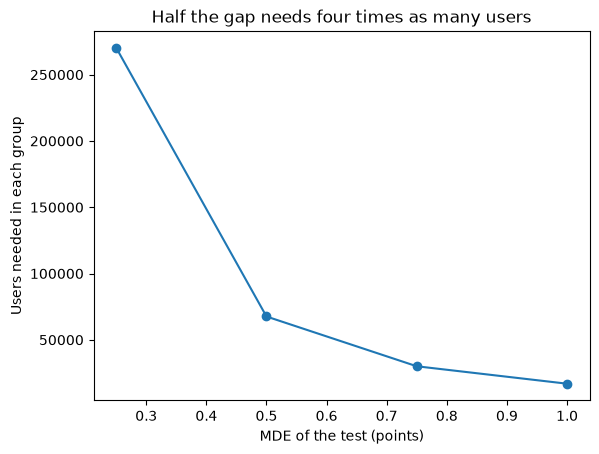

In [39]:
points = np.array([0.25, 0.5, 0.75, 1.0])

users = pd.Series(
    16 * baseline * (1 - baseline) / (points / 100) ** 2,
    index=points
)

ax = users.plot(marker="o")

ax.set_title("Half the gap needs four times as many users")
ax.set_xlabel("MDE of the test (points)")
ax.set_ylabel("Users needed in each group")

ax.figure.savefig(FIGURES / "day-16-plan.png", bbox_inches="tight")

plt.show()

Created a line chart to show how the required sample size changes with the minimum detectable effect (MDE). The chart demonstrates that smaller improvements require much larger sample sizes. For example, detecting half the gap requires four times as many users.

In [40]:
#0.a
mde = 0.003

needed = 16 * baseline * (1 - baseline) / mde ** 2

round(needed)


187733

For a smaller MDE of 0.3 percentage points, the test requires approximately 18,773 users in each group.

In [41]:
#0.a
round(needed / 6400, 1)

29.3

At 6,400 users per group per day, the required sample size takes approximately 2.9 days. The test should run for one full week to cover all days of the week.

## Part 1 — The test's data

In [42]:
ab = pd.read_csv(RAW_AB / "ab_data.csv", parse_dates=["timestamp"])

ab.head(3)

,user_id,timestamp,group,landing_page,converted
0,851104,2017-01-21 22:11:48.556739,control,old_page,0
1,804228,2017-01-12 08:01:45.159739,control,old_page,0
2,661590,2017-01-11 16:55:06.154213,treatment,new_page,0


Loaded the A/B testing dataset from the raw data folder using Pandas. Converted the timestamp column to a datetime type and inspected the first three rows to understand the dataset structure and its columns.

In [43]:
ab.shape

(294478, 5)

Checked the dataset dimensions using `shape`. The dataset contains 294,478 rows and 5 columns, representing the recorded user activity during the A/B test.

In [44]:
ab["timestamp"].agg(["min", "max"])

min   2017-01-02 13:42:05.378582
max   2017-01-24 13:41:54.460509
Name: timestamp, dtype: datetime64[us]

Used `agg()` with `min` and `max` to find the earliest and latest timestamps. The test ran from January 2 to January 24, 2017, covering 22 days, or 3 full weeks and 1 additional day.

In [45]:
ab["group"].value_counts()

group
treatment    147276
control      147202
Name: count, dtype: int64

Used `value_counts()` to count the records in each test group. The control group contains 147,202 rows, and the treatment group contains 147,276 rows. Both groups exceed the planned sample size of 67,584 users.

In [46]:
#1.a
ab["converted"].mean()

np.float64(0.11965919355605512)

Calculated the overall conversion rate using the mean of the binary `converted` column. The result was approximately 11.97%, which is very close to the planned baseline of 12%.

## Part 2 — The result

In [47]:
ab.groupby("group")["converted"].agg(
    ["size", "sum", "mean"]
).round(5)

,size,sum,mean
group,,,
control,147202,17723,0.12040
treatment,147276,17514,0.11892


Grouped the users by their test group and calculated the number of records, total conversions, and conversion rate using `size`, `sum`, and `mean`. The control group had a conversion rate of 12.04%, while the treatment group had a slightly lower rate of 11.89%.

In [48]:
model = smf.ols("converted ~ group", data=ab).fit()

model.params.round(5)

Intercept             0.12040
group[T.treatment]   -0.00148
dtype: float64

Fitted an OLS regression model using `converted` as the outcome and `group` as the explanatory variable. The model used the control group as its reference. The treatment coefficient was approximately -0.00148, meaning the new page had a conversion rate about 0.15 percentage points lower than the old page.

In [49]:
model.conf_int().round(5)

,0,1
Intercept,0.11874,0.12206
group[T.treatment],-0.00382,0.00086


Calculated the 95% confidence intervals for the regression coefficients using `conf_int()`. The treatment effect ranged from -0.00382 to 0.00086. Since the interval includes zero, the results do not rule out the possibility of no difference between the two pages.

In [50]:
model.pvalues.round(2)

Intercept             0.00
group[T.treatment]    0.22
dtype: float64

Retrieved the P-values for the regression coefficients. The treatment effect had a P-value of 0.22, which is higher than the 0.05 significance level. Therefore, the test does not provide sufficient statistical evidence of a difference between the old and new pages.

In [51]:
#2.a
gap = model.params["group[T.treatment]"]

low, high = model.conf_int().loc["group[T.treatment]"]

p_value = model.pvalues["group[T.treatment]"]

gap, low, high, p_value

(np.float64(-0.001479599794078215),
 -0.00382411069848894,
 0.00086491111033251,
 np.float64(0.21611748562493188))

No, we cannot conclude that the new page is worse. Although its conversion rate was slightly lower, the 95% confidence interval includes zero and the P-value is 0.22, which is higher than 0.05. Therefore, the test does not provide sufficient evidence of a real difference between the two pages.

Reviewed the treatment coefficient, its confidence interval, and its P-value. The results show a slightly negative estimated gap, but there is not enough statistical evidence to conclude that the new page performs worse than the old page.

## Part 3 — The gap in business terms

In [52]:
gap = model.params["group[T.treatment]"] * 100

low, high = model.conf_int().loc["group[T.treatment]"] * 100

round(gap, 2), round(low, 2), round(high, 2)

(np.float64(-0.15), -0.38, 0.09)

### Converting the Gap into Percentage Points

The regression coefficient and its confidence interval were originally expressed as decimal shares. I multiplied them by 100 to convert them into percentage points.

The estimated gap was -0.15 points, with a 95% confidence interval ranging from -0.38 to +0.09 points.

This means the treatment group had a slightly lower conversion rate than the control group, and the interval includes both negative and small positive effects.

In [53]:
round(gap * 1000), round(low * 1000), round(high * 1000)

(-148, -382, 86)

### Converting the Gap into Buyers

I converted the percentage-point gap and its confidence interval into buyer counts for every 100,000 users.

The estimated result is 148 fewer buyers with the new page.

The 95% confidence interval ranges from 382 fewer buyers to 86 additional buyers. The business target was 500 additional buyers, so even the best end of the interval is far below the target.

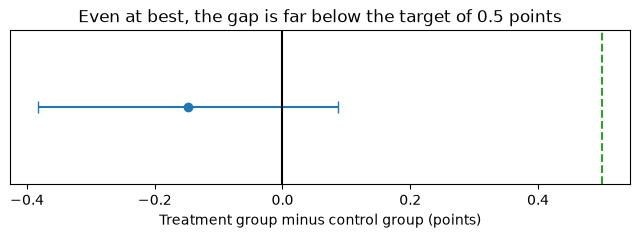

In [54]:
fig, ax = plt.subplots(figsize=(8, 2))

ax.errorbar(gap, 0, xerr=high - gap, fmt="o", capsize=4)

ax.axvline(0, color="black")

ax.axvline(0.5, color="tab:green", linestyle="--")

ax.set_yticks([])

ax.set_title("Even at best, the gap is far below the target of 0.5 points")

ax.set_xlabel("Treatment group minus control group (points)")

fig.savefig(FIGURES / "day-16-decision.png", bbox_inches="tight")

plt.show()

### Visualizing the Result Against the Business Target

I created an error-bar chart to compare the estimated treatment effect and its 95% confidence interval with the business target.

The black vertical line represents no difference between the two pages, while the green dashed line represents the target of +0.5 percentage points.

The entire confidence interval is below the business target. Even the best possible end of the interval (+0.09 points) does not reach the target.

In [55]:
#3.a
profit_per_buyer = 10

best_profit = high * 1000 * profit_per_buyer
worst_profit = low * 1000 * profit_per_buyer
estimated_profit = gap * 1000 * profit_per_buyer

round(best_profit), round(worst_profit), round(estimated_profit)

(865, -3824, -1480)

### Exercise 3.a — Business Impact in Profit

Assuming each buyer generates $10 in profit:

- Best case: approximately $865 in additional profit.
- Worst case: approximately $3,824 less profit.
- Estimated result: approximately $1,480 less profit.

These estimates are based on the buyer-count range from the previous step.

The best-case outcome is approximately $860 in additional profit for every 100,000 users.

The worst-case outcome is approximately $3,820 less profit. Based on the estimated gap, the new page would result in approximately $1,480 less profit.

## Part 4 — Was the test big enough?

In [56]:
group_size = pd.Series(
    [10000, 67584, 147202, 147202 + 14 * 6400],
    index=["a small test", "the plan", "this test", "two more weeks"],
)

mdes = np.sqrt(16 * baseline * (1 - baseline) / group_size) * 100

mdes.round(2)

a small test      1.30
the plan          0.50
this test         0.34
two more weeks    0.27
dtype: float64

### Calculating the Minimum Detectable Effect (MDE)

I calculated the MDE for four different sample sizes using the Rule of 16.

The results were:

- A small test: 1.30 points.
- The original plan: 0.50 points.
- The current test: 0.34 points.
- After two additional weeks: 0.27 points.

A larger sample size allows the experiment to detect smaller effects. The current test has an MDE of 0.34 points, which is smaller than the business target of 0.5 points.

### Was the Test Big Enough?

The current test was large enough because its MDE was 0.34 percentage points, which is smaller than the business target of 0.5 points.

The confidence interval from Part 3 also had an upper bound of only +0.09 points, which is below the target.

Adding two more weeks would reduce the MDE to 0.27 points, but the current test already had enough users to evaluate the business target. Therefore, extending the test is not necessary based on the current results.

In [57]:
#4.a
mde = 0.0015

needed = 16 * baseline * (1 - baseline) / mde ** 2

np.ceil(needed)

np.float64(750934.0)

For an MDE of 0.15 percentage points, each group needs approximately 750,934 users.

With 6,400 users arriving in each group per day, the test would take approximately 118 days to collect the required sample size.

In [58]:
#4.a
days = needed / 6400

round(days, 1), np.ceil(days)

(117.3, np.float64(118.0))

### Exercise 4.a — Smaller MDE

I calculated the required sample size for an MDE of 0.15 percentage points using the Rule of 16.

Each group needs approximately 750,934 users.

At a rate of 6,400 users per group per day, the experiment would need approximately 118 days to collect enough users.


##5.a
### Exercise 5.a — Applying the Decision Rules

| Test | Gap | Confidence Interval | Decision |
|---|---:|---:|---|
| Test 1 | +0.7 points | +0.4 to +1.0 | Switch to the new page |
| Test 2 | +0.2 points | -0.2 to +0.6 | Not sure — Plan a bigger test |
| Test 3 | +0.3 points | +0.15 to +0.45 | Keep the old page |

**Explanation:**

- Test 1 meets the decision rule because the confidence interval is entirely above zero and the estimated gap reaches the business target.
- Test 2 is uncertain because the confidence interval includes zero and the estimated result does not reach the target.
- Test 3 shows a positive effect, but the entire confidence interval remains below the business target.

**Final Decision:**

The shop should keep the old landing page. The new page did not demonstrate the required improvement of 0.5 percentage points. The upper confidence limit was only +0.09 points, which is still below the target.